In [15]:
# ⭐ Project 2: Loan Approval Prediction
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

data = pd.read_csv("loan_approval_dataset.csv")
df = pd.DataFrame(data)
df2 = df.copy()


In [16]:
# Take columns and value to strips
df2.columns=df2.columns.str.strip()
column_strip = ["education","self_employed","loan_status"]
for col in column_strip:
    df2[col]=df2[col].str.strip()
df2.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [17]:
# EDA process
print(df2.head())
print(df2.shape)
print(df2.info())
print(df2.describe())
print(df2.isnull().sum())
print(df2.columns)

   loan_id  no_of_dependents     education self_employed  income_annum  \
0        1                 2      Graduate            No       9600000   
1        2                 0  Not Graduate           Yes       4100000   
2        3                 3      Graduate            No       9100000   
3        4                 3      Graduate            No       8200000   
4        5                 5  Not Graduate           Yes       9800000   

   loan_amount  loan_term  cibil_score  residential_assets_value  \
0     29900000         12          778                   2400000   
1     12200000          8          417                   2700000   
2     29700000         20          506                   7100000   
3     30700000          8          467                  18200000   
4     24200000         20          382                  12400000   

   commercial_assets_value  luxury_assets_value  bank_asset_value loan_status  
0                 17600000             22700000           8000000 

In [21]:
# Categorical Data into Numerical Data
df2["education"] = df2["education"].map({"Graduate":1,"Not Graduate":0})
df2["self_employed"] = df2["self_employed"].map({"Yes":1,"No":0})
#df2["loan_status"] = df2["loan_status"].map({"Approved":1,"Rejected":0})
df2.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [22]:
# Model Train Test Split
x = df2[['education',
         'self_employed',
         'income_annum',
         'loan_amount',
         'loan_term',
         'cibil_score',]]
y = df2['loan_status']

In [23]:

x_train,x_test,y_train,y_test = train_test_split(x, y, test_size=0.20, random_state=42)

model = LogisticRegression()
model.fit(x_train,y_train)



LogisticRegression()

In [25]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test,y_pred)

print("The model prediction :",y_pred[0])
print("The model accuracy   :",accuracy*100,"\n")

new_loan_df = {
    "education"    :[int(input("you are Graduate press:1 , Not Graduate press:0 :"))],
    "self_employed":[int(input("you are employee : Yes press:1 , No press:0     :"))],
    "income_annum" :[int(input("Enter your annual income                        :"))],
    "loan_amount"  :[int(input("Enter your loan amount                          :"))],
    "loan_term"    :[int(input("Enter your loan repayment months                :"))],
    "cibil_score"  :[int(input("Enter your cibil score                          :"))]
    }
new_loan = pd.DataFrame(new_loan_df)
y_pre = model.predict(new_loan)

print("\n-----------------------------")
print("Your loan Application has :")
print(f"       {y_pre[0]}")
print("-----------------------------")

The model prediction : Rejected
The model accuracy   : 79.27400468384074 

you are Graduate press:1 , Not Graduate press:0 :1
you are employee : Yes press:1 , No press:0     :0
Enter your annual income                        :20000
Enter your loan amount                          :10000
Enter your loan repayment months                :15
Enter your cibil score                          :700

-----------------------------
Your loan Application has :
       Approved
-----------------------------


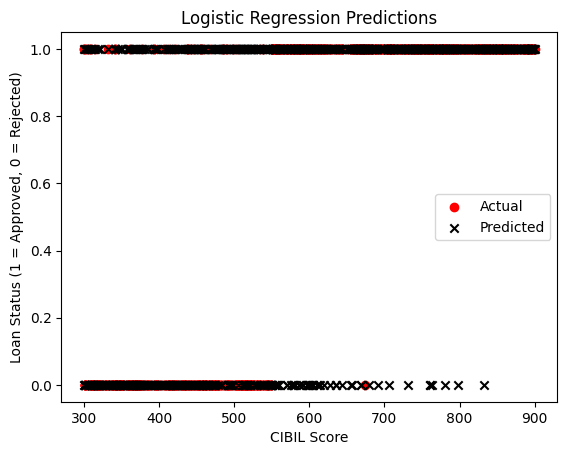

In [36]:
# Logistic regression Graph
import matplotlib.pyplot as plt
import numpy as np

y_test_num = y_test.map({"Approved": 1, "Rejected": 0})
y_pred_num = np.array([1 if pred == "Approved" else 0 for pred in y_pred])

plt.scatter(x_test['cibil_score'], y_test_num, color="red", label="Actual")
plt.scatter(x_test['cibil_score'], y_pred_num, color="black", label="Predicted", marker='x')

plt.xlabel("CIBIL Score")
plt.ylabel("Loan Status (1 = Approved, 0 = Rejected)")
plt.title("Logistic Regression Predictions")
plt.legend()
plt.show()